# 15. Falki, sieci neuronowe i modele językowe (LLM)

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-15.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})

# Dane z obserwatorium SDO używane w tym rozdziale.
# Courtesy of NASA/SDO and the AIA, EVE, and HMI science teams
DANE = "dane/sdo-20240115.npz"
if not os.path.exists(DANE):                 # np. Google Colab: pobranie z repozytorium
    import urllib.request
    os.makedirs("dane", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/main/dane/sdo-20240115.npz", DANE)

# Tekst do uczenia modelu językowego: Darwin, On the Origin of Species (1859), fragment.
TEKST = "dane/darwin.txt"
if not os.path.exists(TEKST):                 # np. Google Colab: pobranie z repozytorium
    import urllib.request
    os.makedirs("dane", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/main/dane/darwin.txt", TEKST)


## Programy z tekstu rozdziału

### Kod 15.1. Transformata rozpraszania sygnału: niezmienniczość i stabilność

In [2]:
import numpy as np
from scipy.special import betainc

def bank(N, J):
    """Analityczne filtry oktawowe o oknach Meyera (por. kod 14.2)."""
    nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))
    f = np.fft.fftfreq(N)
    u = np.log2(np.maximum(f, 1e-12)/0.5)
    G = [np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                  np.sin(np.pi/2*nu(u + j + 1))) for j in range(J)]
    G[0] = np.sin(np.pi/2*nu(u + 1))
    return np.array(G)*(f > 0)

def rozpraszanie(x, G):
    """Współczynniki rzędu 1 i 2 uśrednione po całym sygnale."""
    U1 = np.abs(np.fft.ifft(np.fft.fft(x)[None]*G))        # |x * psi_j|
    S2 = [np.abs(np.fft.ifft(np.fft.fft(U1[j])[None]*G[j + 1:])).mean(axis=1)
          for j in range(len(G) - 1)]                      # ||x*psi_j|*psi_i|
    return np.concatenate([U1.mean(axis=1)] + S2)

N = 4096
t = np.arange(N)/N
def sygnal(t):
    obwiednia = np.exp(-((t - 0.5)/0.15)**2)
    return obwiednia*(np.sin(2*np.pi*40*t) + 0.8*np.sin(2*np.pi*310*t + 1)
                      + 0.6*np.sin(2*np.pi*900*t))

x, G = sygnal(t), bank(N, 9)
widmo = lambda v: np.abs(np.fft.rfft(v))
zmiana = lambda a, b: np.linalg.norm(a - b)/np.linalg.norm(a)
print("liczba współczynników:", len(rozpraszanie(x, G)))
y = np.roll(x, 37)
print(f"przesunięcie o 37 próbek: sygnał {zmiana(x, y):.3f}, moduł widma "
      f"{zmiana(widmo(x), widmo(y)):.3f}, rozpraszanie "
      f"{zmiana(rozpraszanie(x, G), rozpraszanie(y, G)):.3f}")
for eps in (0.005, 0.01, 0.02, 0.05):
    y = sygnal(0.5 + (t - 0.5)*(1 + eps))                  # rozciągnięcie
    print(f"rozciągnięcie o {100*eps:3.1f}%:  sygnał {zmiana(x, y):.3f}, "
          f"moduł widma {zmiana(widmo(x), widmo(y)):.3f}, rozpraszanie "
          f"{zmiana(rozpraszanie(x, G), rozpraszanie(y, G)):.3f}")

liczba współczynników: 45
przesunięcie o 37 próbek: sygnał 1.483, moduł widma 0.000, rozpraszanie 0.000
rozciągnięcie o 0.5%:  sygnał 0.688, moduł widma 0.688, rozpraszanie 0.014
rozciągnięcie o 1.0%:  sygnał 0.889, moduł widma 0.889, rozpraszanie 0.029
rozciągnięcie o 2.0%:  sygnał 1.023, moduł widma 1.023, rozpraszanie 0.060
rozciągnięcie o 5.0%:  sygnał 1.146, moduł widma 1.146, rozpraszanie 0.157


### Kod 15.2. Rozpraszanie obrazów: wycinki obserwacji Słońca i ich surogaty o tym samym widmie

In [3]:
import numpy as np
from scipy.special import betainc

nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))

def rama(n, J=4, K=8):
    """Filtry G[j, k] ramy kierunkowej i kwadrat filtru reszty."""
    ky, kx = np.meshgrid(np.fft.fftfreq(n), np.fft.fftfreq(n),
                         indexing="ij")
    u = np.log2(np.maximum(np.hypot(kx, ky), 1e-12)/0.5)
    R = np.array([np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                           np.sin(np.pi/2*nu(u + j + 1)))
                  for j in range(J)])          # okna promieniowe
    R[0] = np.sin(np.pi/2*nu(u + 1))
    R[:, (kx == -0.5) | (ky == -0.5)] = 0      # prążki bez pary
    kat = np.arctan2(ky, kx)[None] - np.pi*np.arange(K)[:, None, None]/K
    d = np.abs(np.angle(np.exp(1j*kat)))       # odległość kątowa
    A = np.cos(np.pi/2*nu(d*K/np.pi))*(d < np.pi/K)    # okna kątowe
    return R[:, None]*A[None], 1 - np.sum(R**2, axis=0)


def rozpraszanie2(X, G):
    """Zwraca S1[i, j, k] oraz unormowane współczynniki rzędu 2."""
    J = G.shape[0]
    U1 = np.abs(np.fft.ifft2(np.fft.fft2(X)[:, None, None]*G[None]))
    S1 = U1.mean(axis=(3, 4))
    F1, S2 = np.fft.fft2(U1), []
    for j1 in range(J - 1):
        for j2 in range(j1 + 1, J):                # tylko skale większe
            U2 = np.abs(np.fft.ifft2(F1[:, j1, :, None]*G[None, None, j2]))
            S2.append((U2.mean(axis=(3, 4))/S1[:, j1, :, None])
                      .reshape(len(X), -1))
    return S1.reshape(len(X), -1), np.concatenate(S2, axis=1)

def wycinki(A, n=64):
    """64 wycinki n na n, każdy o zerowej średniej i wariancji 1."""
    P = np.nan_to_num(A.astype(float)).reshape(8, n, 8, n)
    P = P.swapaxes(1, 2).reshape(-1, n, n)
    P = P - P.mean(axis=(1, 2), keepdims=True)
    return P/P.std(axis=(1, 2), keepdims=True)

def surogat(X, rng):
    """Te same moduły widma, fazy losowe; bez nieciągłości na brzegach."""
    M = np.concatenate([X, X[:, :, ::-1]], axis=2)     # odbicia lustrzane
    M = np.concatenate([M, M[:, ::-1]], axis=1)        # 2n na 2n, okresowy
    faza = np.angle(np.fft.fft2(rng.normal(size=M.shape)))
    Y = np.fft.ifft2(np.abs(np.fft.fft2(M))*np.exp(1j*faza)).real
    Y = Y[:, :X.shape[1], :X.shape[2]]                 # wycinek n na n
    Y = Y - Y.mean(axis=(1, 2), keepdims=True)
    return Y/Y.std(axis=(1, 2), keepdims=True)

def trafnosc(C, y, rng, ile=10, proby=200):
    """Klasyfikator najbliższej średniej, losowe podziały danych."""
    wynik = 0
    for proba in range(proby):
        ucz = np.concatenate([rng.choice(np.nonzero(y == c)[0], ile,
                                         replace=False) for c in (0, 1)])
        test = np.setdiff1d(np.arange(len(y)), ucz)
        grupy = [C[ucz][y[ucz] == c] for c in (0, 1)]
        skala = np.sqrt(np.mean([g.var(axis=0) for g in grupy], axis=0))
        Z = (C - C[ucz].mean(axis=0))/(skala + 1e-9)
        srednie = np.stack([Z[ucz][y[ucz] == c].mean(axis=0) for c in (0, 1)])
        odl = ((Z[test][:, None] - srednie[None])**2).sum(axis=2)
        wynik += np.mean(np.argmin(odl, axis=1) == y[test])/proby
    return 100*wynik

dane = np.load("dane/sdo-20240115.npz")
G = rama(64, 3, 6)[0]
r = np.hypot(*np.meshgrid(np.fft.fftfreq(64), np.fft.fftfreq(64)))
pierscienie = [(r >= a) & (r < a + 0.04) for a in np.arange(0.01, 0.49, 0.04)]
rng = np.random.default_rng(0)
y = np.repeat([0, 1], 64)
print("obraz        kurtoza  widmo  rząd 1  rząd 2   (trafność w %)")
for nazwa, A in (("aia171", np.sqrt(np.clip(dane["aia171"], 0, None))),
                 ("aia94", np.sqrt(np.clip(dane["aia94"], 0, None))),
                 ("fotosfera", dane["hmi_ic_plama"]),
                 ("magnetogram", dane["hmi_m"])):
    X0 = wycinki(A)
    X = np.concatenate([X0, surogat(X0, rng)])     # 64 prawdziwe, 64 surogaty
    moc = np.abs(np.fft.fft2(X))**2
    widmo = np.log(np.stack([moc[:, p].mean(axis=1) for p in pierscienie],
                            axis=1))
    S1, S2 = rozpraszanie2(X, G)
    print(f"{nazwa:12s} {np.mean(X0**4):6.2f} {trafnosc(widmo, y, rng):6.1f} "
          f"{trafnosc(np.log(S1), y, rng):7.1f} "
          f"{trafnosc(np.log(S2), y, rng):7.1f}")

obraz        kurtoza  widmo  rząd 1  rząd 2   (trafność w %)
aia171         3.16   49.0    53.9    61.9
aia94          3.78   49.4    50.2    50.4
fotosfera      3.30   48.4    53.8    55.0
magnetogram   33.20   48.3    68.3    83.6


### Kod 15.3. Uczenie kroków liftingu z danych

In [4]:
import numpy as np
import pywt

def okno_e(e, r):
    """Kolumny: próbki parzyste e[n-r+1], …, e[n+r] (okresowo)."""
    return np.stack([np.roll(e, -i) for i in range(-r + 1, r + 1)], axis=1)

def okno_d(d, r):
    return np.stack([np.roll(d, -i) for i in range(-r, r)], axis=1)

def ucz(x, r):
    """Predykcja o 2r współczynnikach i aktualizacja o 2, z danych x."""
    e, o = x[0::2], x[1::2]
    p = np.linalg.lstsq(okno_e(e, r), o, rcond=None)[0]    # (15.3)
    d = o - okno_e(e, r) @ p
    X = np.fft.rfft(x)
    X[len(x)//4 + 1:] = 0                      # idealny filtr połówkowy
    cel = np.fft.irfft(X, len(x))[0::2]
    u = np.linalg.lstsq(okno_d(d, 1), cel - e, rcond=None)[0]
    return p, u

def analiza(x, p, u):
    e, o = x[0::2], x[1::2]
    d = o - okno_e(e, len(p)//2) @ p           # predykcja
    return e + okno_d(d, 1) @ u, d             # aktualizacja

def synteza(s, d, p, u):
    e = s - okno_d(d, 1) @ u
    x = np.empty(2*len(s))
    x[0::2], x[1::2] = e, d + okno_e(e, len(p)//2) @ p
    return x

def blad_kompresji(x, kroki, udzial=0.1):
    """Błąd po zachowaniu zadanej części współczynników."""
    s, detale = x, []
    for p, u in kroki:
        s, d = analiza(s, p, u)
        detale.append(d)
    wagi = [2**((j - 1)/2) for j in range(len(kroki))]     # normalizacja
    wszystkie = np.concatenate([w*d for w, d in zip(wagi, detale)]
                               + [2**(len(kroki)/2)*s])
    prog = np.sort(np.abs(wszystkie))[-int(udzial*len(x))]
    for (p, u), d, w in zip(kroki[::-1], detale[::-1], wagi[::-1]):
        s = synteza(s, np.where(np.abs(w*d) >= prog, d, 0), p, u)
    return 100*np.linalg.norm(s - x)/np.linalg.norm(x)

rng = np.random.default_rng(0)
# 1. dane wielomianowe: nauczona predykcja jest znaną falką
x = np.polyval(rng.normal(size=4), np.linspace(-1, 1, 256))
e, o = x[0::2], x[1::2]
p = np.linalg.lstsq(okno_e(e, 2)[2:-2], o[2:-2], rcond=None)[0]
print("wielomiany stopnia 3:", p.round(4), " × 16 =", (16*p).round(2))

def drgania(N, rng):
    """Dwie składowe o wolno zmiennej częstotliwości i krótkie impulsy."""
    n = np.arange(N)
    faza = 2*np.pi*np.cumsum(0.11 + 0.01*np.sin(2*np.pi*n/700
                                               + rng.uniform(0, 6)))
    x = (1 + 0.3*np.sin(2*np.pi*n/300))*np.sin(faza) + 0.5*np.sin(2.02*faza)
    for k in rng.choice(N - 12, 6, replace=False):
        x[k:k + 12] += 1.5*np.exp(-np.arange(12)/3)
    return x + 0.02*rng.normal(size=N)

ekg = pywt.data.ecg().astype(float)
ekg -= ekg.mean()
rng = np.random.default_rng(1)
zbiory = {"EKG": (ekg[:512], ekg[512:]),
          "drgania": (drgania(2048, rng), drgania(2048, rng))}
stale = {"5/3": (np.array([1, 1])/2, np.array([1, 1])/4),
         "(-1, 9, 9, -1)/16": (np.array([-1, 9, 9, -1])/16,
                               np.array([1, 1])/4)}
for nazwa, (uczacy, testowy) in zbiory.items():
    print(f"{nazwa}: detale poziomu 1 [% energii] i błąd kompresji [%]")
    warianty = {k: [v]*4 for k, v in stale.items()}
    for r in (2, 3):
        pierwszy = ucz(uczacy, r)
        warianty[f"uczona {2*r}+2, wspólna"] = [pierwszy]*4
        kroki, s = [], uczacy
        for poziom in range(4):                # osobno na każdym poziomie
            kroki.append(ucz(s, r))
            s = analiza(s, *kroki[-1])[0]
        warianty[f"uczona {2*r}+2, poziomami"] = kroki
    for opis, kroki in warianty.items():
        d = analiza(testowy, *kroki[0])[1]
        print(f"   {opis:24s} {100*np.sum(d**2)/np.sum(testowy**2):6.2f} "
              f"{blad_kompresji(testowy, kroki):7.2f}")
print("odwracalność:", np.allclose(
    synteza(*analiza(ekg, *kroki[0]), *kroki[0]), ekg))

wielomiany stopnia 3: [-0.0625  0.5625  0.5625 -0.0625]  × 16 = [-1.  9.  9. -1.]
EKG: detale poziomu 1 [% energii] i błąd kompresji [%]
   5/3                        0.22    6.43
   (-1, 9, 9, -1)/16          0.10    6.13
   uczona 4+2, wspólna        0.09    6.11
   uczona 4+2, poziomami      0.09   10.96
   uczona 6+2, wspólna        0.09    6.69
   uczona 6+2, poziomami      0.09   10.86
drgania: detale poziomu 1 [% energii] i błąd kompresji [%]
   5/3                        9.07   62.59
   (-1, 9, 9, -1)/16          6.07   59.21
   uczona 4+2, wspólna        4.05   64.17
   uczona 4+2, poziomami      4.05   53.34
   uczona 6+2, wspólna        2.41   53.12
   uczona 6+2, poziomami      2.41   41.88
odwracalność: True


### Kod 15.4. Sieć z neuronami falkowymi i sieć z neuronami tanh o tej samej liczbie parametrów

In [5]:
import numpy as np

x = np.linspace(0, 1, 512)
y = (np.sin(2*np.pi*x) + 0.8*np.exp(-((x - 0.3)/0.02)**2)
     + 0.5*(x > 0.7))                          # fala, wąski garb i skok

def adam(par, strata_i_gradient, kroki, tempo=0.01):
    """Optymalizator Adam; zwraca parametry i przebieg błędu."""
    m = [np.zeros_like(p) for p in par]
    v = [np.zeros_like(p) for p in par]
    przebieg = []
    for t in range(1, kroki + 1):
        strata, grad = strata_i_gradient(par)
        for i, g in enumerate(grad):
            m[i] = 0.9*m[i] + 0.1*g
            v[i] = 0.999*v[i] + 0.001*g**2
            par[i] -= tempo*(m[i]/(1 - 0.9**t))/(
                np.sqrt(v[i]/(1 - 0.999**t)) + 1e-8)
        przebieg.append(np.sqrt(strata))
    return par, np.array(przebieg)

def siec_tanh(par):
    """f(x) = sum w2 tanh(w1 x + b1) + b2; błąd i jego gradient."""
    w1, b1, w2, b2 = par
    h = np.tanh(np.outer(x, w1) + b1)
    r = h @ w2 + b2 - y
    gh = np.outer(r, w2)*(1 - h**2)
    return np.mean(r**2), [2*(x @ gh)/len(x), 2*gh.mean(axis=0),
                           2*(h.T @ r)/len(x), np.array(2*r.mean())]

psi = lambda u: (1 - u**2)*np.exp(-u**2/2)     # „meksykański kapelusz”
dpsi = lambda u: (u**3 - 3*u)*np.exp(-u**2/2)

def siec_falkowa(par):
    """f(x) = sum w psi(a (x - b)) + c0 x + c1; błąd i gradient."""
    a, b, w, c = par
    u = (x[:, None] - b)*a
    r = psi(u) @ w + c[0]*x + c[1] - y
    gu = np.outer(r, w)*dpsi(u)
    return np.mean(r**2), [2*np.mean(gu*(x[:, None] - b), axis=0),
                           2*np.mean(-gu*a, axis=0),
                           2*(psi(u).T @ r)/len(x),
                           np.array([2*np.mean(r*x), 2*r.mean()])]

H, kroki = 24, 3000
wyniki = {"tanh": [], "falkowa": []}
for ziarno in range(5):
    rng = np.random.default_rng(ziarno)
    par = [8*rng.normal(size=H), 4*rng.normal(size=H),
           0.3*rng.normal(size=H), np.array(0.0)]
    wyniki["tanh"].append(adam(par, siec_tanh, kroki)[1])
    # falki na siatce diadycznej: 2, 4 i 8 falek coraz węższych, reszta wąska
    a = np.concatenate([np.full(2**j, 3*2.0**j) for j in (1, 2, 3)]
                       + [np.full(H - 14, 48.0)])
    b = np.concatenate([(np.arange(2**j) + 0.5)/2**j for j in (1, 2, 3)]
                       + [rng.uniform(0, 1, H - 14)])
    par = [a, b, 0.01*rng.normal(size=H), np.zeros(2)]
    wyniki["falkowa"].append(adam(par, siec_falkowa, kroki)[1])
print(f"parametrów: tanh {3*H + 1}, falkowa {3*H + 2}")
print("pierwiastek błędu średniokwadratowego (mediana z 5 prób):")
for nazwa, przebiegi in wyniki.items():
    med = np.median(przebiegi, axis=0)
    print(f"   {nazwa:8s}" + "".join(f"  {k}: {med[k - 1]:.3f}"
                                    for k in (100, 300, 1000, 3000)))

parametrów: tanh 73, falkowa 74
pierwiastek błędu średniokwadratowego (mediana z 5 prób):
   tanh      100: 0.297  300: 0.138  1000: 0.120  3000: 0.093
   falkowa   100: 0.034  300: 0.028  1000: 0.024  3000: 0.019


### Kod 15.5. Miniaturowy model językowy: przewidywanie następnego znaku przy różnych opisach kontekstu

In [6]:
import numpy as np

tekst = open("dane/darwin.txt", encoding="utf8").read()
znaki = sorted(set(tekst))
V = len(znaki)
ids = np.array([znaki.index(c) for c in tekst])        # tekst jako liczby
N = len(ids)
podzial = int(0.9*N)                           # 90% do uczenia, 10% do testu

def model(okna, d=16, H=128, kroki=8000, partia=256, tempo=0.003):
    """Uczy model przewidujący następny znak. Każde okno (a, b) daje
    średnią osadzeń znaków odległych wstecz o a+1, …, b."""
    rng = np.random.default_rng(0)
    zasieg, F = max(b for a, b in okna), len(okna)*d
    par = [0.1*rng.normal(size=(V, d)),                # osadzenia znaków
           rng.normal(size=(F, H))/np.sqrt(F), np.zeros(H),
           rng.normal(size=(H, V))/np.sqrt(H), np.zeros(V)]
    m = [np.zeros_like(p) for p in par]
    v = [np.zeros_like(p) for p in par]

    def przod(poz, ciag=ids):
        E, W1, b1, W2, b2 = par
        wstecz = ciag[poz[:, None] - 1 - np.arange(zasieg)]
        wiersz = V*np.arange(len(poz))[:, None]
        C = [np.bincount((wstecz[:, a:b] + wiersz).ravel(),
                         minlength=V*len(poz)).reshape(-1, V)/(b - a)
             for a, b in okna]                 # udziały znaków w oknach
        X = np.concatenate([c @ E for c in C], axis=1)
        h = np.tanh(X @ W1 + b1)
        z = h @ W2 + b2
        p = np.exp(z - z.max(axis=1, keepdims=True))
        return C, X, h, p/p.sum(axis=1, keepdims=True)

    for t in range(1, kroki + 1):
        poz = rng.integers(zasieg, podzial, partia)
        C, X, h, p = przod(poz)
        dz = p
        dz[np.arange(partia), ids[poz]] -= 1   # gradient entropii krzyżowej
        dz /= partia
        dh = (dz @ par[3].T)*(1 - h**2)
        dX = dh @ par[1].T
        grad = [sum(c.T @ dX[:, k*d:(k + 1)*d] for k, c in enumerate(C)),
                X.T @ dh, dh.sum(axis=0), h.T @ dz, dz.sum(axis=0)]
        for i, g in enumerate(grad):           # krok algorytmu Adam
            m[i] = 0.9*m[i] + 0.1*g
            v[i] = 0.999*v[i] + 0.001*g*g
            par[i] -= tempo*(m[i]/(1 - 0.9**t))/(
                np.sqrt(v[i]/(1 - 0.999**t)) + 1e-8)

    test = np.arange(podzial, len(ids))
    p = np.concatenate([przod(c)[3][np.arange(len(c)), ids[c]]
                        for c in np.array_split(test, 20)])
    return -np.mean(np.log2(p)), par, przod

czestosc = np.bincount(ids[:podzial], minlength=V) + 1
print(f"znaków: {N}, alfabet: {V}; bez kontekstu "
      f"{-np.mean(np.log2((czestosc/czestosc.sum())[ids[podzial:]])):.2f}"
      " bita na znak")
warianty = {
    "2 znaki": [(0, 1), (1, 2)],
    "2 znaki + średnia z 30": [(0, 1), (1, 2), (2, 32)],
    "2 znaki + skale 2, 4, 8, 16": [(0, 1), (1, 2), (2, 4), (4, 8),
                                    (8, 16), (16, 32)],
    "4 znaki": [(j, j + 1) for j in range(4)],
    "8 znaków": [(j, j + 1) for j in range(8)]}
wyniki = {}
for nazwa, okna in warianty.items():
    wyniki[nazwa], par, przod = model(okna)
    print(f"{nazwa:28s} zasięg {max(b for a, b in okna):2d}, parametrów "
          f"{sum(q.size for q in par):5d}: {wyniki[nazwa]:.2f} bita na znak")

rng = np.random.default_rng(1)                 # ostatni model pisze sam
ciag = list(ids[podzial + 1000:podzial + 1008])        # początek: 8 znaków
for i in range(70):
    p = przod(np.array([len(ciag)]), np.array(ciag + [0]))[3][0]
    ciag.append(rng.choice(V, p=p))            # losowanie następnego znaku
print("".join(znaki[i] for i in ciag))

znaków: 219888, alfabet: 29; bez kontekstu 4.18 bita na znak
2 znaki                      zasięg  2, parametrów  8429: 2.61 bita na znak
2 znaki + średnia z 30       zasięg 32, parametrów 10477: 2.58 bita na znak
2 znaki + skale 2, 4, 8, 16  zasięg 32, parametrów 16621: 2.06 bita na znak
4 znaki                      zasięg  4, parametrów 12525: 1.96 bita na znak
8 znaków                     zasięg  8, parametrów 20717: 1.99 bita na znak
fford theter, the pollen many other criest variations of species, thair seems.


## Funkcje pomocnicze

Funkcje i dane, z których korzystają rozwiązania ćwiczeń.

In [7]:
from scipy.special import betainc

def bank(N, J):
    """Analityczne filtry oktawowe o oknach Meyera (por. kod 14.2)."""
    nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))
    f = np.fft.fftfreq(N)
    u = np.log2(np.maximum(f, 1e-12)/0.5)
    G = [np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                  np.sin(np.pi/2*nu(u + j + 1))) for j in range(J)]
    G[0] = np.sin(np.pi/2*nu(u + 1))
    return np.array(G)*(f > 0)

def rozpraszanie(x, G):
    """Współczynniki rzędu 1 i 2 uśrednione po całym sygnale."""
    U1 = np.abs(np.fft.ifft(np.fft.fft(x)[None]*G))        # |x * psi_j|
    S2 = [np.abs(np.fft.ifft(np.fft.fft(U1[j])[None]*G[j + 1:])).mean(axis=1)
          for j in range(len(G) - 1)]                      # ||x*psi_j|*psi_i|
    return np.concatenate([U1.mean(axis=1)] + S2)

nu = lambda x: betainc(4, 4, np.clip(x, 0, 1))

def rama(n, J=4, K=8):
    """Filtry G[j, k] ramy kierunkowej i kwadrat filtru reszty."""
    ky, kx = np.meshgrid(np.fft.fftfreq(n), np.fft.fftfreq(n),
                         indexing="ij")
    u = np.log2(np.maximum(np.hypot(kx, ky), 1e-12)/0.5)
    R = np.array([np.where(u >= -j, np.cos(np.pi/2*nu(u + j)),
                           np.sin(np.pi/2*nu(u + j + 1)))
                  for j in range(J)])          # okna promieniowe
    R[0] = np.sin(np.pi/2*nu(u + 1))
    R[:, (kx == -0.5) | (ky == -0.5)] = 0      # prążki bez pary
    kat = np.arctan2(ky, kx)[None] - np.pi*np.arange(K)[:, None, None]/K
    d = np.abs(np.angle(np.exp(1j*kat)))       # odległość kątowa
    A = np.cos(np.pi/2*nu(d*K/np.pi))*(d < np.pi/K)    # okna kątowe
    return R[:, None]*A[None], 1 - np.sum(R**2, axis=0)


def rozpraszanie2(X, G):
    """Zwraca S1[i, j, k] oraz unormowane współczynniki rzędu 2."""
    J = G.shape[0]
    U1 = np.abs(np.fft.ifft2(np.fft.fft2(X)[:, None, None]*G[None]))
    S1 = U1.mean(axis=(3, 4))
    F1, S2 = np.fft.fft2(U1), []
    for j1 in range(J - 1):
        for j2 in range(j1 + 1, J):                # tylko skale większe
            U2 = np.abs(np.fft.ifft2(F1[:, j1, :, None]*G[None, None, j2]))
            S2.append((U2.mean(axis=(3, 4))/S1[:, j1, :, None])
                      .reshape(len(X), -1))
    return S1.reshape(len(X), -1), np.concatenate(S2, axis=1)

def wycinki(A, n=64):
    """64 wycinki n na n, każdy o zerowej średniej i wariancji 1."""
    P = np.nan_to_num(A.astype(float)).reshape(8, n, 8, n)
    P = P.swapaxes(1, 2).reshape(-1, n, n)
    P = P - P.mean(axis=(1, 2), keepdims=True)
    return P/P.std(axis=(1, 2), keepdims=True)

def surogat(X, rng):
    """Te same moduły widma, fazy losowe; bez nieciągłości na brzegach."""
    M = np.concatenate([X, X[:, :, ::-1]], axis=2)     # odbicia lustrzane
    M = np.concatenate([M, M[:, ::-1]], axis=1)        # 2n na 2n, okresowy
    faza = np.angle(np.fft.fft2(rng.normal(size=M.shape)))
    Y = np.fft.ifft2(np.abs(np.fft.fft2(M))*np.exp(1j*faza)).real
    Y = Y[:, :X.shape[1], :X.shape[2]]                 # wycinek n na n
    Y = Y - Y.mean(axis=(1, 2), keepdims=True)
    return Y/Y.std(axis=(1, 2), keepdims=True)

def trafnosc(C, y, rng, ile=10, proby=200):
    """Klasyfikator najbliższej średniej, losowe podziały danych."""
    wynik = 0
    for proba in range(proby):
        ucz = np.concatenate([rng.choice(np.nonzero(y == c)[0], ile,
                                         replace=False) for c in (0, 1)])
        test = np.setdiff1d(np.arange(len(y)), ucz)
        grupy = [C[ucz][y[ucz] == c] for c in (0, 1)]
        skala = np.sqrt(np.mean([g.var(axis=0) for g in grupy], axis=0))
        Z = (C - C[ucz].mean(axis=0))/(skala + 1e-9)
        srednie = np.stack([Z[ucz][y[ucz] == c].mean(axis=0) for c in (0, 1)])
        odl = ((Z[test][:, None] - srednie[None])**2).sum(axis=2)
        wynik += np.mean(np.argmin(odl, axis=1) == y[test])/proby
    return 100*wynik

def okno_e(e, r):
    """Kolumny: próbki parzyste e[n-r+1], …, e[n+r] (okresowo)."""
    return np.stack([np.roll(e, -i) for i in range(-r + 1, r + 1)], axis=1)

def okno_d(d, r):
    return np.stack([np.roll(d, -i) for i in range(-r, r)], axis=1)

def ucz(x, r):
    """Predykcja o 2r współczynnikach i aktualizacja o 2, z danych x."""
    e, o = x[0::2], x[1::2]
    p = np.linalg.lstsq(okno_e(e, r), o, rcond=None)[0]    # (15.3)
    d = o - okno_e(e, r) @ p
    X = np.fft.rfft(x)
    X[len(x)//4 + 1:] = 0                      # idealny filtr połówkowy
    cel = np.fft.irfft(X, len(x))[0::2]
    u = np.linalg.lstsq(okno_d(d, 1), cel - e, rcond=None)[0]
    return p, u

def analiza(x, p, u):
    e, o = x[0::2], x[1::2]
    d = o - okno_e(e, len(p)//2) @ p           # predykcja
    return e + okno_d(d, 1) @ u, d             # aktualizacja

def synteza(s, d, p, u):
    e = s - okno_d(d, 1) @ u
    x = np.empty(2*len(s))
    x[0::2], x[1::2] = e, d + okno_e(e, len(p)//2) @ p
    return x

def blad_kompresji(x, kroki, udzial=0.1):
    """Błąd po zachowaniu zadanej części współczynników."""
    s, detale = x, []
    for p, u in kroki:
        s, d = analiza(s, p, u)
        detale.append(d)
    wagi = [2**((j - 1)/2) for j in range(len(kroki))]     # normalizacja
    wszystkie = np.concatenate([w*d for w, d in zip(wagi, detale)]
                               + [2**(len(kroki)/2)*s])
    prog = np.sort(np.abs(wszystkie))[-int(udzial*len(x))]
    for (p, u), d, w in zip(kroki[::-1], detale[::-1], wagi[::-1]):
        s = synteza(s, np.where(np.abs(w*d) >= prog, d, 0), p, u)
    return 100*np.linalg.norm(s - x)/np.linalg.norm(x)

def drgania(N, rng):
    """Dwie składowe o wolno zmiennej częstotliwości i krótkie impulsy."""
    n = np.arange(N)
    faza = 2*np.pi*np.cumsum(0.11 + 0.01*np.sin(2*np.pi*n/700
                                               + rng.uniform(0, 6)))
    x = (1 + 0.3*np.sin(2*np.pi*n/300))*np.sin(faza) + 0.5*np.sin(2.02*faza)
    for k in rng.choice(N - 12, 6, replace=False):
        x[k:k + 12] += 1.5*np.exp(-np.arange(12)/3)
    return x + 0.02*rng.normal(size=N)

def adam(par, strata_i_gradient, kroki, tempo=0.01):
    """Optymalizator Adam; zwraca parametry i przebieg błędu."""
    m = [np.zeros_like(p) for p in par]
    v = [np.zeros_like(p) for p in par]
    przebieg = []
    for t in range(1, kroki + 1):
        strata, grad = strata_i_gradient(par)
        for i, g in enumerate(grad):
            m[i] = 0.9*m[i] + 0.1*g
            v[i] = 0.999*v[i] + 0.001*g**2
            par[i] -= tempo*(m[i]/(1 - 0.9**t))/(
                np.sqrt(v[i]/(1 - 0.999**t)) + 1e-8)
        przebieg.append(np.sqrt(strata))
    return par, np.array(przebieg)

def siec_tanh(par):
    """f(x) = sum w2 tanh(w1 x + b1) + b2; błąd i jego gradient."""
    w1, b1, w2, b2 = par
    h = np.tanh(np.outer(x, w1) + b1)
    r = h @ w2 + b2 - y
    gh = np.outer(r, w2)*(1 - h**2)
    return np.mean(r**2), [2*(x @ gh)/len(x), 2*gh.mean(axis=0),
                           2*(h.T @ r)/len(x), np.array(2*r.mean())]

def siec_falkowa(par):
    """f(x) = sum w psi(a (x - b)) + c0 x + c1; błąd i gradient."""
    a, b, w, c = par
    u = (x[:, None] - b)*a
    r = psi(u) @ w + c[0]*x + c[1] - y
    gu = np.outer(r, w)*dpsi(u)
    return np.mean(r**2), [2*np.mean(gu*(x[:, None] - b), axis=0),
                           2*np.mean(-gu*a, axis=0),
                           2*(psi(u).T @ r)/len(x),
                           np.array([2*np.mean(r*x), 2*r.mean()])]

psi = lambda u: (1 - u**2)*np.exp(-u**2/2)
dpsi = lambda u: (u**3 - 3*u)*np.exp(-u**2/2)

In [8]:
tekst = open("dane/darwin.txt", encoding="utf8").read()
znaki = sorted(set(tekst))
V = len(znaki)
ids = np.array([znaki.index(c) for c in tekst])        # tekst jako liczby
N = len(ids)
podzial = int(0.9*N)                           # 90% do uczenia, 10% do testu

def model(okna, d=16, H=128, kroki=8000, partia=256, tempo=0.003):
    """Uczy model przewidujący następny znak. Każde okno (a, b) daje
    średnią osadzeń znaków odległych wstecz o a+1, …, b."""
    rng = np.random.default_rng(0)
    zasieg, F = max(b for a, b in okna), len(okna)*d
    par = [0.1*rng.normal(size=(V, d)),                # osadzenia znaków
           rng.normal(size=(F, H))/np.sqrt(F), np.zeros(H),
           rng.normal(size=(H, V))/np.sqrt(H), np.zeros(V)]
    m = [np.zeros_like(p) for p in par]
    v = [np.zeros_like(p) for p in par]

    def przod(poz, ciag=ids):
        E, W1, b1, W2, b2 = par
        wstecz = ciag[poz[:, None] - 1 - np.arange(zasieg)]
        wiersz = V*np.arange(len(poz))[:, None]
        C = [np.bincount((wstecz[:, a:b] + wiersz).ravel(),
                         minlength=V*len(poz)).reshape(-1, V)/(b - a)
             for a, b in okna]                 # udziały znaków w oknach
        X = np.concatenate([c @ E for c in C], axis=1)
        h = np.tanh(X @ W1 + b1)
        z = h @ W2 + b2
        p = np.exp(z - z.max(axis=1, keepdims=True))
        return C, X, h, p/p.sum(axis=1, keepdims=True)

    for t in range(1, kroki + 1):
        poz = rng.integers(zasieg, podzial, partia)
        C, X, h, p = przod(poz)
        dz = p
        dz[np.arange(partia), ids[poz]] -= 1   # gradient entropii krzyżowej
        dz /= partia
        dh = (dz @ par[3].T)*(1 - h**2)
        dX = dh @ par[1].T
        grad = [sum(c.T @ dX[:, k*d:(k + 1)*d] for k, c in enumerate(C)),
                X.T @ dh, dh.sum(axis=0), h.T @ dz, dz.sum(axis=0)]
        for i, g in enumerate(grad):           # krok algorytmu Adam
            m[i] = 0.9*m[i] + 0.1*g
            v[i] = 0.999*v[i] + 0.001*g*g
            par[i] -= tempo*(m[i]/(1 - 0.9**t))/(
                np.sqrt(v[i]/(1 - 0.999**t)) + 1e-8)

    test = np.arange(podzial, len(ids))
    p = np.concatenate([przod(c)[3][np.arange(len(c)), ids[c]]
                        for c in np.array_split(test, 20)])
    return -np.mean(np.log2(p)), par, przod

WARIANTY = {"2 znaki": [(0, 1), (1, 2)], "2 znaki + średnia z 30": [(0, 1), (1, 2), (2, 32)],
            "2 znaki + skale 2, 4, 8, 16": [(0, 1), (1, 2), (2, 4), (4, 8), (8, 16), (16, 32)],
            "4 znaki": [(j, j + 1) for j in range(4)], "8 znaków": [(j, j + 1) for j in range(8)]}

In [9]:
# Courtesy of NASA/SDO and the AIA, EVE, and HMI science teams
SDO = np.load(DANE)
OBRAZY = {"aia171": np.sqrt(np.clip(SDO["aia171"], 0, None)), "aia94": np.sqrt(np.clip(SDO["aia94"], 0, None)),
          "fotosfera": SDO["hmi_ic_plama"], "magnetogram": SDO["hmi_m"]}

## Ćwiczenia i rozwiązania

### Funkcje wspólne dla rozwiązań

In [10]:
# Rozwiązania korzystają z funkcji z części „Funkcje pomocnicze”
# (bank, rozpraszanie, rama, rozpraszanie2, wycinki, surogat, trafnosc, ucz, analiza,
# synteza, adam, siec_tanh, siec_falkowa, model) oraz ze słowników OBRAZY i WARIANTY – trzeba je uruchomić wcześniej.
N = 4096
t = np.arange(N)/N
def sygnal(t):
    return np.exp(-((t - 0.5)/0.15)**2)*(np.sin(2*np.pi*40*t) + 0.8*np.sin(2*np.pi*310*t + 1)
                                         + 0.6*np.sin(2*np.pi*900*t))
zmiana = lambda a, b: np.linalg.norm(a - b)/np.linalg.norm(a)

### Ćwiczenie 15.1
Utwórz surogat sygnału z kodu 15.1, zastępując fazy jego widma losowymi, i porównaj współczynniki rozpraszania rzędu pierwszego i drugiego sygnału i surogatu. Które różnią się bardziej?

### Rozwiązanie 15.1

In [11]:
x1 = sygnal(t)
Gb = bank(N, 9)
rng = np.random.default_rng(0)
X = np.fft.rfft(x1)
faza = rng.uniform(0, 2*np.pi, len(X)); faza[0] = 0
sur = np.fft.irfft(np.abs(X)*np.exp(1j*faza), N)
S, Ss = rozpraszanie(x1, Gb), rozpraszanie(sur, Gb)
print(f"moduł widma: {zmiana(np.abs(X), np.abs(np.fft.rfft(sur))):.3f}, rząd 1: "
      f"{zmiana(S[:9], Ss[:9]):.3f}, rząd 2: {zmiana(S[9:], Ss[9:]):.3f}")
# Sygnał ma jedną wspólną obwiednię, a surogat jest rozłożony równomiernie w czasie.
# Najbardziej różnią się współczynniki rzędu 2, które opisują zmienność obwiedni.

moduł widma: 0.000, rząd 1: 0.549, rząd 2: 17.587


### Ćwiczenie 15.2
Sprawdź, że zmiana współczynników rozpraszania w kodzie 15.1 jest w przybliżeniu proporcjonalna do rozciągnięcia w zakresie od 0,1% do 5%.

### Rozwiązanie 15.2

In [12]:
x1 = sygnal(t)
S = rozpraszanie(x1, Gb)
for eps in (0.001, 0.002, 0.005, 0.01, 0.02, 0.05):
    z = zmiana(S, rozpraszanie(sygnal(0.5 + (t - 0.5)*(1 + eps)), Gb))
    print(f"rozciągnięcie {100*eps:4.1f}%: zmiana {z:.4f}, zmiana/rozciągnięcie {z/eps:.2f}")

rozciągnięcie  0.1%: zmiana 0.0029, zmiana/rozciągnięcie 2.85
rozciągnięcie  0.2%: zmiana 0.0057, zmiana/rozciągnięcie 2.86
rozciągnięcie  0.5%: zmiana 0.0144, zmiana/rozciągnięcie 2.88
rozciągnięcie  1.0%: zmiana 0.0292, zmiana/rozciągnięcie 2.92
rozciągnięcie  2.0%: zmiana 0.0596, zmiana/rozciągnięcie 2.98
rozciągnięcie  5.0%: zmiana 0.1569, zmiana/rozciągnięcie 3.14


### Ćwiczenie 15.3
Powtórz doświadczenie z kodu 15.2 dla 3 i dla 30 przykładów uczących w klasie. Jak zmienia się trafność dla fotosfery?

### Rozwiązanie 15.3

In [13]:
G = rama(64, 3, 6)[0]
y = np.repeat([0, 1], 64)
rng = np.random.default_rng(0)
X0 = wycinki(OBRAZY["fotosfera"]); Xm = wycinki(OBRAZY["magnetogram"])
for nazwa, P in (("fotosfera", X0), ("magnetogram", Xm)):
    S2 = np.log(rozpraszanie2(np.concatenate([P, surogat(P, rng)]), G)[1])
    print(nazwa, "".join(f"  {ile} przykładów: {trafnosc(S2, y, rng, ile=ile, proby=100):.1f}%"
                         for ile in (3, 10, 30)))

fotosfera   3 przykładów: 51.7%  10 przykładów: 57.0%  30 przykładów: 62.4%
magnetogram   3 przykładów: 71.1%  10 przykładów: 82.9%  30 przykładów: 85.3%


### Ćwiczenie 15.4
Zastąp w kodzie 15.2 funkcję `surogat` wersją bez odbić lustrzanych, losującą fazy wprost dla wycinka. Jak zmieniają się trafności i dlaczego?

### Rozwiązanie 15.4

In [14]:
def surogat_prosty(X, rng):
    faza = np.angle(np.fft.fft2(rng.normal(size=X.shape)))
    Y = np.fft.ifft2(np.abs(np.fft.fft2(X))*np.exp(1j*faza)).real
    return Y/Y.std(axis=(1, 2), keepdims=True)
rng = np.random.default_rng(0)
for nazwa, A in OBRAZY.items():
    P = wycinki(A)
    wyn = [trafnosc(np.log(rozpraszanie2(np.concatenate([P, f(P, rng)]), G)[1]), y, rng, proby=100)
           for f in (surogat, surogat_prosty)]
    print(f"{nazwa:12s} z odbiciami {wyn[0]:5.1f}%, bez odbić {wyn[1]:5.1f}%")
# Bez odbić trafność rośnie dla obrazów o wyraźnej nieciągłości na brzegach wycinka:
# klasyfikator rozpoznaje artefakt przygotowania danych (zob. uwagę o brzegach).

aia171       z odbiciami  61.8%, bez odbić  82.8%
aia94        z odbiciami  51.9%, bez odbić  48.6%
fotosfera    z odbiciami  55.8%, bez odbić  96.1%
magnetogram  z odbiciami  82.7%, bez odbić  85.6%


### Ćwiczenie 15.5
Naucz predykcję o dwóch współczynnikach na sinusoidzie o częstotliwości *f* cykli na próbkę. Sprawdź, że oba współczynniki są równe $1/(2\cos 2\pi f)$ i że detale są zerami.

### Rozwiązanie 15.5

In [15]:
n = np.arange(512)
for f in (0.05, 0.11, 0.2):
    xs = np.sin(2*np.pi*f*n + 0.4)
    e, o = xs[0::2], xs[1::2]
    A = np.stack([e[:-1], e[1:]], axis=1)
    p = np.linalg.lstsq(A, o[:-1], rcond=None)[0]
    print(f"f = {f}: p = {p.round(5)}, 1/(2 cos 2πf) = {1/(2*np.cos(2*np.pi*f)):.5f}, "
          f"największy detal {np.abs(o[:-1] - A @ p).max():.1e}")
# Z tożsamości sin(a - b) + sin(a + b) = 2 sin(a) cos(b): próbka nieparzysta jest
# sumą dwóch sąsiednich parzystych podzieloną przez 2 cos(2πf).

f = 0.05: p = [0.52573 0.52573], 1/(2 cos 2πf) = 0.52573, największy detal 1.4e-14
f = 0.11: p = [0.64892 0.64892], 1/(2 cos 2πf) = 0.64892, największy detal 3.4e-14
f = 0.2: p = [1.61803 1.61803], 1/(2 cos 2πf) = 1.61803, największy detal 1.5e-13


### Ćwiczenie 15.6
Wyznacz falkę odpowiadającą predykcji nauczonej na zapisie EKG: wykonaj transformatę odwrotną jednego współczynnika detalu z trzeciego poziomu. Porównaj ją z falką otrzymaną dla filtru $(-1, 9, 9, -1)/16$.

### Rozwiązanie 15.6

nauczona na EKG p = [-0.092  0.595  0.58  -0.092] u = [0.295 0.307]
(-1, 9, 9, -1)/16 p = [-0.062  0.562  0.562 -0.062] u = [0.25 0.25]


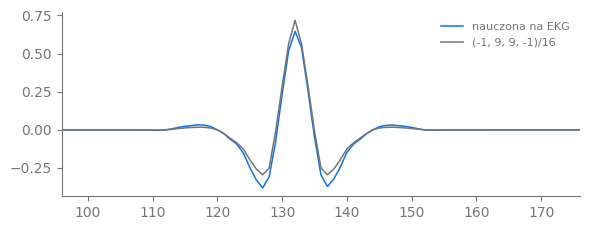

In [16]:
ekg = pywt.data.ecg().astype(float); ekg -= ekg.mean()
fig, ax = plt.subplots(figsize=(6, 2.4))
for nazwa, (p, u), kolor in (("nauczona na EKG", ucz(ekg[:512], 2), NIEBIESKI),
                             ("(-1, 9, 9, -1)/16", (np.array([-1, 9, 9, -1])/16, np.array([1, 1])/4), SZARY)):
    s, d = np.zeros(32), np.zeros(32); d[16] = 1
    for poziom in range(3):
        s = synteza(s, d, p, u); d = np.zeros(len(s))
    ax.plot(s, color=kolor, lw=1.1, label=nazwa)
    print(nazwa, "p =", np.round(p, 3), "u =", np.round(u, 3))
ax.set_xlim(96, 176); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
# Obie falki są prawie identyczne: dla sygnału EKG uczenie odtwarza falkę klasyczną.

### Ćwiczenie 15.7
Powtórz doświadczenie z kodu 15.4 dla funkcji gładkiej $\sin 2\pi x + 0{,}5 \cos 6\pi x$. Która sieć jest dokładniejsza?

### Rozwiązanie 15.7

In [17]:
x = np.linspace(0, 1, 512)
y = np.sin(2*np.pi*x) + 0.5*np.cos(6*np.pi*x)
H, kroki = 24, 3000
wyn = {"tanh": [], "falkowa": []}
for ziarno in range(3):
    rng = np.random.default_rng(ziarno)
    wyn["tanh"].append(adam([8*rng.normal(size=H), 4*rng.normal(size=H), 0.3*rng.normal(size=H),
                             np.array(0.0)], siec_tanh, kroki)[1][-1])
    a = np.concatenate([np.full(2**j, 3*2.0**j) for j in (1, 2, 3)] + [np.full(H - 14, 48.0)])
    b = np.concatenate([(np.arange(2**j) + 0.5)/2**j for j in (1, 2, 3)] + [rng.uniform(0, 1, H - 14)])
    wyn["falkowa"].append(adam([a, b, 0.01*rng.normal(size=H), np.zeros(2)], siec_falkowa, kroki)[1][-1])
print({k: round(float(np.median(v)), 4) for k, v in wyn.items()})

{'tanh': 0.017, 'falkowa': 0.0019}


### Ćwiczenie 15.8
Zamroź w sieci falkowej z kodu 15.4 skale i położenia na siatce diadycznej o 30 falkach i wyznacz same wagi metodą najmniejszych kwadratów. Porównaj błąd z wynikiem uczenia wszystkich parametrów.

### Rozwiązanie 15.8

In [18]:
x = np.linspace(0, 1, 512)
y = np.sin(2*np.pi*x) + 0.8*np.exp(-((x - 0.3)/0.02)**2) + 0.5*(x > 0.7)
a = np.concatenate([np.full(2**j, 3*2.0**j) for j in (1, 2, 3, 4)])        # 2 + 4 + 8 + 16 = 30 falek
b = np.concatenate([(np.arange(2**j) + 0.5)/2**j for j in (1, 2, 3, 4)])
A = np.column_stack([psi((x[:, None] - b)*a), x, np.ones_like(x)])
w = np.linalg.lstsq(A, y, rcond=None)[0]
print(f"30 falek na stałej siatce (32 parametry liniowe): błąd {np.sqrt(np.mean((A @ w - y)**2)):.4f}")
print("sieć falkowa z kodu 15.4 (24 falki, 74 parametry): błąd około 0,020")
# Stała siatka daje błąd kilkakrotnie większy: wąski garb o szerokości 0,02 nie trafia
# w żaden węzeł siatki. Uczenie położeń i skal pozwala falkom dopasować się do szczegółu.

30 falek na stałej siatce (32 parametry liniowe): błąd 0.0732
sieć falkowa z kodu 15.4 (24 falki, 74 parametry): błąd około 0,020


### Ćwiczenie 15.9
Zmień w kodzie 15.5 wariant wieloskalowy tak, aby dokładnie podawane były cztery ostatnie znaki, a po nich średnie z odcinków o długościach 4, 8, 16 i 32. Czy wynik jest lepszy niż dla ośmiu znaków podanych dokładnie?

### Rozwiązanie 15.9

In [19]:
okna = [(j, j + 1) for j in range(4)] + [(4, 8), (8, 16), (16, 32), (32, 64)]
bity = model(okna)[0]
print(f"4 znaki + skale 4, 8, 16, 32 (zasięg 64): {bity:.2f} bita na znak")
print(f"4 znaki: {model(WARIANTY['4 znaki'])[0]:.2f}, 8 znaków: {model(WARIANTY['8 znaków'])[0]:.2f}")
# Różnice są rzędu setnych części bita: przy czterech znakach podanych dokładnie
# ta mała sieć nie potrafi już wykorzystać dalszego kontekstu, niezależnie od jego opisu.

4 znaki + skale 4, 8, 16, 32 (zasięg 64): 2.00 bita na znak
4 znaki: 1.96, 8 znaków: 1.99


### Ćwiczenie 15.10
Narysuj macierz podobieństw (kosinusów kątów) między osadzeniami znaków nauczonymi przez model z kodu 15.5. Które znaki model uznał za podobne?

### Rozwiązanie 15.10

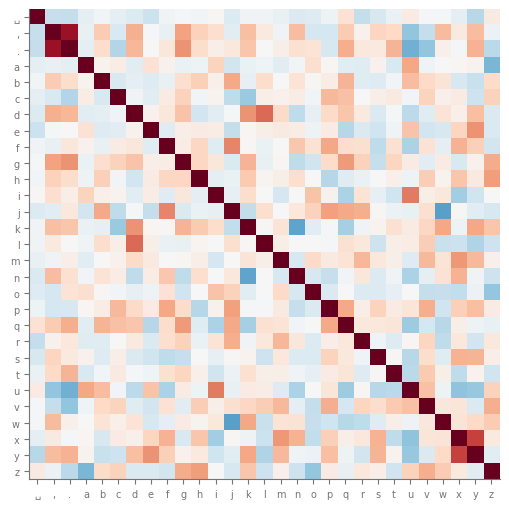

a → najbliższe: u i o e
e → najbliższe: y u x a
o → najbliższe: i j m a
y → najbliższe: x e k .
średnie podobieństwo: samogłoska–samogłoska 0.13, samogłoska–spółgłoska -0.04


In [20]:
E = model(WARIANTY["4 znaki"])[1][0]
En = E/np.linalg.norm(E, axis=1, keepdims=True)
S = En @ En.T
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.imshow(S, cmap="RdBu_r", vmin=-1, vmax=1)
etykiety = [z if z != " " else "␣" for z in znaki]
ax.set_xticks(range(V)); ax.set_xticklabels(etykiety, fontsize=7)
ax.set_yticks(range(V)); ax.set_yticklabels(etykiety, fontsize=7)
fig.tight_layout(); plt.show()
np.fill_diagonal(S, -1)
for z in "aeoy":
    k = znaki.index(z)
    print(z, "→ najbliższe:", " ".join(znaki[i] for i in np.argsort(S[k])[::-1][:4]))
samogloski = [znaki.index(z) for z in "aeiouy"]
inne = [i for i in range(V) if i not in samogloski and znaki[i] not in " ,."]
print(f"średnie podobieństwo: samogłoska–samogłoska {S[np.ix_(samogloski, samogloski)][~np.eye(6, dtype=bool)].mean():.2f}, "
      f"samogłoska–spółgłoska {S[np.ix_(samogloski, inne)].mean():.2f}")
# Model sam, z samego przewidywania następnego znaku, pogrupował znaki o podobnej roli:
# samogłoski są do siebie bardziej podobne niż do spółgłosek.